# AI-Generated vs Student-Generated Text Classification Using Machine Learning

**Subject:** Machine Learning Essentials (ECSCI24302)

**Project Type:** Problem-Based Learning (PBL)

## 1. Project Objective

The objective of this project is to develop a Machine Learning model that classifies text as AI-generated or human-written using a suitable dataset.

The project will include data analysis, preprocessing, feature engineering, model training, model evaluation, error analysis, reducing false "AI" flags on human-written text, and deployment using Streamlit.

## 2. Dataset Information

- **Dataset Name:** AI vs Human Text
- **Source:** Kaggle
- **Dataset URL:** https://www.kaggle.com/datasets/shanegerami/ai-vs-human-text

The actual dataset files, columns, labels, and data quality will be checked before starting the analysis.

**Additional human-written data (added during model improvement, Steps 25 to 27):**

- **Blog Authorship Corpus** (blog posts from 2004): https://www.kaggle.com/datasets/rtatman/blog-authorship-corpus
- **BBC Full Text Document Classification** (BBC news articles from 2004 to 2005): https://www.kaggle.com/datasets/alfathterry/bbc-full-text-document-classification

Both were written before AI text generators existed, so they are reliably human-written. They were added because the main dataset's human texts are only student essays.

## 3. Project Workflow

1. Problem Definition
2. Dataset Acquisition
3. Dataset Understanding
4. Data Quality Analysis
5. Exploratory Data Analysis (EDA)
6. Data Preprocessing
7. Feature Engineering and Feature Selection
8. Train-Test Split
9. Baseline Model
10. Training Multiple Machine Learning Models
11. Hyperparameter Tuning
12. Cross-Validation
13. Model Evaluation and Comparison
14. Error Analysis
15. Model Interpretation
16. False-Positive Analysis (human-written text wrongly flagged as AI)
17. Model Improvement: style features, short-text training, and a tuned threshold with an "Uncertain" zone
18. Retraining with Additional Human-Written Data (blogs and news)
19. Final Prediction Demonstration
20. Model Saving and Streamlit Deployment
21. Conclusion and Future Work

## 4. Important Consideration

The model's predictions and estimated AI/human probabilities will be treated as estimates, not as definite proof of who wrote the text. All reported results will come from actual experiments conducted in this notebook.

The final model reports three outcomes (**Human-Written**, **Uncertain**, or **AI-Generated**), so borderline texts are not forced into the AI class. Texts under 50 words are never labelled AI because very short texts cannot be judged reliably.

In [1]:
# Step 2: Download and inspect the dataset
!pip -q install kagglehub
import kagglehub
import os
# Download the dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "shanegerami/ai-vs-human-text"
)
print("Dataset downloaded successfully!")
print("Dataset folder:", dataset_path)
print("\nFiles available in the dataset:")
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        full_path = os.path.join(root, file)
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"{file} | {size_mb:.2f} MB")

Dataset downloaded successfully!
Dataset folder: /kaggle/input/datasets/shanegerami/ai-vs-human-text

Files available in the dataset:
AI_Human.csv | 1059.48 MB


In [2]:

# Step 3: Inspect the dataset without loading the entire CSV

import os
import pandas as pd

csv_path = os.path.join(dataset_path, "AI_Human.csv")

print("File exists:", os.path.exists(csv_path))
print(f"File size: {os.path.getsize(csv_path) / (1024**3):.2f} GB")

# Read only the first 5 rows
df_sample = pd.read_csv(csv_path, nrows=5)

print("\nDataset column names:")
print(df_sample.columns.tolist())

print("\nFirst 5 records:")
display(df_sample)

print("\nColumn data types:")
print(df_sample.dtypes)


File exists: True
File size: 1.03 GB

Dataset column names:
['text', 'generated']

First 5 records:


,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0



Column data types:
text          object
generated    float64
dtype: object


In [3]:

# Step 4: Data quality and label analysis

import pandas as pd

chunk_size = 100_000

total_rows = 0
missing_text = 0
missing_labels = 0
duplicate_text_count = 0
label_counts = {}
label_values = set()

for chunk in pd.read_csv(csv_path, chunksize=chunk_size):
    total_rows += len(chunk)

    # Count missing values
    missing_text += chunk["text"].isna().sum()
    missing_labels += chunk["generated"].isna().sum()

    # Count label values
    counts = chunk["generated"].value_counts(dropna=False)
    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

    label_values.update(chunk["generated"].dropna().unique())

    # Count repeated text within each chunk
    duplicate_text_count += chunk["text"].duplicated().sum()

print("DATASET QUALITY REPORT")
print("-" * 40)
print("Total rows:", total_rows)
print("Total columns: 2")
print("Missing text values:", missing_text)
print("Missing label values:", missing_labels)
print("Repeated text within individual chunks:", duplicate_text_count)

print("\nUnique non-missing label values:", sorted(label_values))
print("\nLabel counts:")
for label, count in sorted(label_counts.items(), key=lambda item: str(item[0])):
    print(f"Label {label}: {count:,} rows ({count / total_rows * 100:.2f}%)")


DATASET QUALITY REPORT
----------------------------------------
Total rows: 487235
Total columns: 2
Missing text values: 0
Missing label values: 0
Repeated text within individual chunks: 0

Unique non-missing label values: [np.float64(0.0), np.float64(1.0)]

Label counts:
Label 0.0: 305,797 rows (62.76%)
Label 1.0: 181,438 rows (37.24%)


## 5. Target Variable and Label Definition

The dataset contains two columns:

- **text:** Contains the text samples used as input features.
- **generated:** Contains the target label for classification.

The target variable has two classes:

- **0:** Human-written text
- **1:** AI-generated text

This is a binary classification problem because the model predicts one of two possible classes.

The dataset contains 305,797 human-written text samples (62.76%) and 181,438 AI-generated text samples (37.24%). Therefore, the dataset has an unequal class distribution, which will be considered during model evaluation.

In [4]:

# Step 6.1: Load a sample for exploratory data analysis

import pandas as pd
import matplotlib.pyplot as plt

# Read a reproducible random sample from the dataset
sample_df = pd.read_csv(csv_path).sample(
    n=20_000,
    random_state=42
).reset_index(drop=True)

# Calculate the number of characters and words in each text
sample_df["text_length"] = sample_df["text"].astype(str).str.len()
sample_df["word_count"] = (
    sample_df["text"].astype(str).str.split().str.len()
)

print("Sample shape:", sample_df.shape)

print("\nText length statistics:")
display(sample_df["text_length"].describe().to_frame())

print("\nWord count statistics:")
display(sample_df["word_count"].describe().to_frame())

print("\nSample records:")
display(sample_df[["text", "generated", "text_length", "word_count"]].head())


Sample shape: (20000, 4)

Text length statistics:


,text_length
count,20000.00000
mean,2261.92355
std,987.72520
min,98.00000
25%,1586.00000
50%,2094.00000
75%,2707.00000
max,9175.00000



Word count statistics:


,word_count
count,20000.000000
mean,391.584050
std,168.975608
min,14.000000
25%,277.000000
50%,361.000000
75%,468.000000
max,1651.000000



Sample records:


,text,generated,text_length,word_count
0,"Real or Fake Feelings\n\n""Imagine being able t...",0.0,2541,414
1,Seeking multiple opinions can help you make be...,0.0,2557,456
2,"ADDRESS_NAME\n\nFebruary 9, 2011\n\nDear TEACH...",0.0,1633,295
3,"Dear, TEACHER_NAME,\n\nTEACHER_NAME I Believe ...",0.0,1170,217
4,Do you believe that there is a computer that c...,0.0,1062,179


Class distribution in the 20,000-record sample:


,Number of records
Human-written,12440
AI-generated,7560


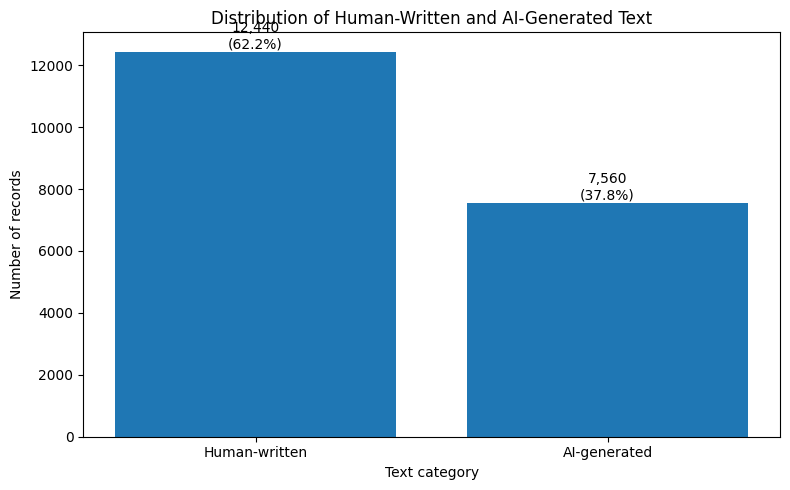

In [5]:

# Step 6.2: Visualize class distribution in the sample

import matplotlib.pyplot as plt

label_names = {
    0: "Human-written",
    1: "AI-generated"
}

class_counts = sample_df["generated"].value_counts().sort_index()
class_counts.index = [
    label_names[int(label)] for label in class_counts.index
]

print("Class distribution in the 20,000-record sample:")
display(class_counts.rename("Number of records").to_frame())

plt.figure(figsize=(8, 5))

bars = plt.bar(class_counts.index, class_counts.values)

plt.title("Distribution of Human-Written and AI-Generated Text")
plt.xlabel("Text category")
plt.ylabel("Number of records")

for bar in bars:
    height = bar.get_height()
    percentage = height / class_counts.sum() * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Word count comparison:


,record_count,mean_words,median_words,min_words,max_words
generated,,,,,
Human-written,12440,421.17,387.0,75,1651
AI-generated,7560,342.90,337.0,14,1029


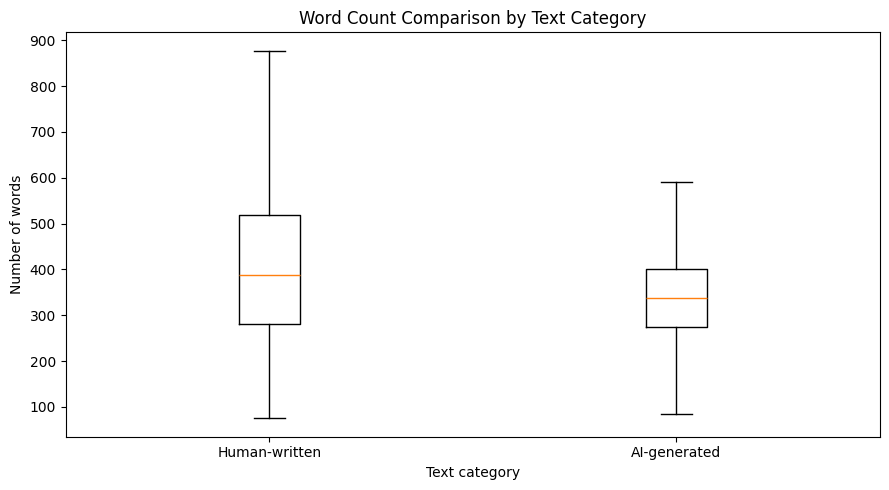

In [6]:

# Step 6.3: Compare text length by category

# Calculate word-count statistics for each class
length_summary = sample_df.groupby("generated").agg(
    record_count=("word_count", "count"),
    mean_words=("word_count", "mean"),
    median_words=("word_count", "median"),
    min_words=("word_count", "min"),
    max_words=("word_count", "max")
)

length_summary.index = length_summary.index.map({
    0.0: "Human-written",
    1.0: "AI-generated"
})

print("Word count comparison:")
display(length_summary.round(2))

# Create a box plot to compare word counts
plt.figure(figsize=(9, 5))

categories = [
    sample_df.loc[sample_df["generated"] == 0, "word_count"],
    sample_df.loc[sample_df["generated"] == 1, "word_count"]
]

plt.boxplot(
    categories,
    tick_labels=["Human-written", "AI-generated"],
    showfliers=False
)

plt.title("Word Count Comparison by Text Category")
plt.xlabel("Text category")
plt.ylabel("Number of words")
plt.tight_layout()
plt.show()


Key observations
1. Human-written texts are longer on average. The average is approximately 421 words for human-written text and 343 words for AI-generated text in this sample.
2. The median shows a similar pattern. Half of the human-written texts have 387 words or fewer, compared with 337 words for AI-generated texts.
3. Human-written text has greater variation in length. Its box plot shows a wider spread of word counts.
4. Word count alone cannot identify the author. These distributions overlap, so some AI-generated texts may be longer than human-written texts and vice versa.

Average text length by category:


,average_words,average_characters
generated,,
Human-written,421.17,2350.27
AI-generated,342.90,2116.55


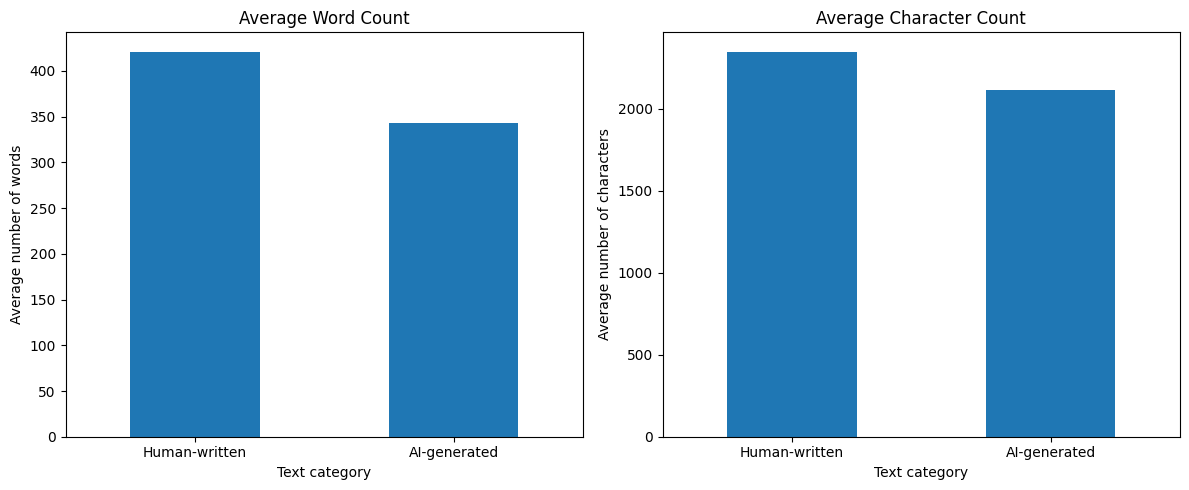

In [7]:

# Step 6.4: Compare average word count and character count

average_lengths = sample_df.groupby("generated").agg(
    average_words=("word_count", "mean"),
    average_characters=("text_length", "mean")
)

average_lengths.index = average_lengths.index.map({
    0.0: "Human-written",
    1.0: "AI-generated"
})

print("Average text length by category:")
display(average_lengths.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

average_lengths["average_words"].plot(
    kind="bar",
    ax=axes[0],
    title="Average Word Count"
)
axes[0].set_xlabel("Text category")
axes[0].set_ylabel("Average number of words")
axes[0].tick_params(axis="x", rotation=0)

average_lengths["average_characters"].plot(
    kind="bar",
    ax=axes[1],
    title="Average Character Count"
)
axes[1].set_xlabel("Text category")
axes[1].set_ylabel("Average number of characters")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Key observations
1. Human-written texts contain approximately 78 more words on average than AI-generated texts in our sample.
2. Human-written texts also contain approximately 234 more characters on average.
3. Both graphs show the same general pattern: human-written texts are longer on average in this sample.
4. These differences alone cannot reliably classify a text. Our machine learning model must learn from the text itself, and we must test how well it performs on unseen records.

## 6. Exploratory Data Analysis (EDA)

### 6.1 Sample Description

A random sample of 20,000 records was selected from the dataset using `random_state=42`. Word count and character count were calculated for each text.

### 6.2 Class Distribution

The sample contained 12,440 human-written texts (62.2%) and 7,560 AI-generated texts (37.8%). The distribution is unequal, with human-written text forming the larger class.

### 6.3 Text Length Analysis

The overall average text length was approximately 2,262 characters and 392 words.

In the sample, human-written texts had an average of 421.17 words and 2,350.27 characters. AI-generated texts had an average of 342.90 words and 2,116.55 characters.

The box plot showed a wider distribution of word counts for human-written texts. However, text lengths varied within both categories, so length alone is not sufficient to determine authorship.

### 6.4 EDA Conclusion

The initial analysis identified an unequal class distribution and differences in average text length between the two categories. These findings will guide later model evaluation. Further data quality checks, duplicate analysis, preprocessing, and text feature extraction are required before model training.

In [8]:

# Step 7.1: Check duplicate text across the entire dataset

import pandas as pd
import hashlib

chunk_size = 50_000

seen_hashes = set()
total_rows_checked = 0
duplicate_text_rows = 0
missing_text_rows = 0

for chunk in pd.read_csv(
    csv_path,
    usecols=["text"],
    chunksize=chunk_size
):
    total_rows_checked += len(chunk)

    missing_text_rows += int(chunk["text"].isna().sum())

    for text_value in chunk["text"].dropna():
        text_hash = hashlib.sha256(
            text_value.encode("utf-8")
        ).hexdigest()

        if text_hash in seen_hashes:
            duplicate_text_rows += 1
        else:
            seen_hashes.add(text_hash)

print("FULL DATASET DUPLICATE CHECK")
print("-" * 40)
print("Rows checked:", f"{total_rows_checked:,}")
print("Missing text rows:", f"{missing_text_rows:,}")
print("Repeated text rows:", f"{duplicate_text_rows:,}")
print("Unique non-missing text hashes:", f"{len(seen_hashes):,}")


FULL DATASET DUPLICATE CHECK
----------------------------------------
Rows checked: 487,235
Missing text rows: 0
Repeated text rows: 0
Unique non-missing text hashes: 487,235


In [9]:

# Step 7.2: Verify label values and repeated text-label pairs

import pandas as pd

chunk_size = 50_000
label_counts = {}
invalid_label_rows = 0
missing_label_rows = 0
repeated_text_label_rows = 0

seen_pairs = set()

for chunk in pd.read_csv(
    csv_path,
    usecols=["text", "generated"],
    chunksize=chunk_size
):
    missing_label_rows += int(chunk["generated"].isna().sum())

    valid_labels = chunk["generated"].isin([0, 1])
    invalid_label_rows += int(
        (~valid_labels & chunk["generated"].notna()).sum()
    )

    counts = chunk["generated"].value_counts(dropna=False)
    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

    for text_value, label in chunk[
        ["text", "generated"]
    ].itertuples(index=False, name=None):
        if pd.isna(text_value) or pd.isna(label):
            continue

        pair = (text_value, label)

        if pair in seen_pairs:
            repeated_text_label_rows += 1
        else:
            seen_pairs.add(pair)

print("LABEL VALIDATION REPORT")
print("-" * 40)
print("Label counts:", label_counts)
print("Missing labels:", missing_label_rows)
print("Invalid label rows:", invalid_label_rows)
print("Repeated text-label pairs:", repeated_text_label_rows)
print("Expected labels: 0 = Human-written, 1 = AI-generated")


LABEL VALIDATION REPORT
----------------------------------------
Label counts: {1.0: 181438, 0.0: 305797}
Missing labels: 0
Invalid label rows: 0
Repeated text-label pairs: 0
Expected labels: 0 = Human-written, 1 = AI-generated


## 7. Data Quality and Validation

The complete dataset of 487,235 records was checked using chunk-based processing with a chunk size of 50,000 records.

The analysis found no missing text values, missing target labels, invalid labels, exact duplicate texts, or repeated text-label pairs.

The target variable contains two valid classes: 0 for human-written text and 1 for AI-generated text. The dataset contains 305,797 human-written records and 181,438 AI-generated records.

Chunk-based processing was used to reduce memory usage while analysing the complete CSV file. The initial EDA was performed on a reproducible random sample of 20,000 records.

In [10]:

# Step 8.1: Inspect raw text before preprocessing

# Show 2 human-written examples
print("=" * 70)
print("HUMAN-WRITTEN TEXT EXAMPLES")
print("=" * 70)

human_examples = sample_df[sample_df["generated"] == 0]["text"].head(2)

for i, text in enumerate(human_examples, start=1):
    print(f"\nExample {i}:")
    print(str(text)[:1000])
    print("\n" + "-" * 70)


# Show 2 AI-generated examples
print("\n" + "=" * 70)
print("AI-GENERATED TEXT EXAMPLES")
print("=" * 70)

ai_examples = sample_df[sample_df["generated"] == 1]["text"].head(2)

for i, text in enumerate(ai_examples, start=1):
    print(f"\nExample {i}:")
    print(str(text)[:1000])
    print("\n" + "-" * 70)


HUMAN-WRITTEN TEXT EXAMPLES

Example 1:
Real or Fake Feelings

"Imagine being able to detect exactly hoe other people are feeling, even then they are trying to hide their emotions" (D'Alto). The article by Nick D'Alto,

"Making Mona Lisa Smile" is about a née software, the Facial Action Coding System which can recognize emotions based on muscle movements. Some people think this technology can be useful for many industries, however it can have negative effects on some. The use of this technology to read the emotional expressions of students in a classroom is not valuable.

Students may have personal issues, and it is not necessary for classroom's to know the emotions an individual is going through. As the article explains hoe muscle movements connect at hoe someone feels, it states, "Beckman has classified six basic emotions happiness, surprise, anger, disgust, fear, and sadness..." ’D'Alto). This demonstrates that the technology can only detect a fee emotion. The technology may get con

In [11]:

# Step 8.2: Check empty and whitespace-only text

import pandas as pd

chunk_size = 50_000
total_rows = 0
empty_text_rows = 0
whitespace_only_rows = 0
non_string_rows = 0

for chunk in pd.read_csv(
    csv_path,
    usecols=["text"],
    chunksize=chunk_size
):
    total_rows += len(chunk)

    text = chunk["text"]

    empty_text_rows += int((text == "").sum())
    whitespace_only_rows += int(
        (text.notna() & text.str.strip().eq("")).sum()
    )
    non_string_rows += int(
        (text.notna() & ~text.map(lambda value: isinstance(value, str))).sum()
    )

print("TEXT VALIDATION REPORT")
print("-" * 40)
print("Total rows checked:", f"{total_rows:,}")
print("Empty text rows:", empty_text_rows)
print("Whitespace-only text rows:", whitespace_only_rows)
print("Non-string text rows:", non_string_rows)


TEXT VALIDATION REPORT
----------------------------------------
Total rows checked: 487,235
Empty text rows: 0
Whitespace-only text rows: 4
Non-string text rows: 0


In [12]:

# Step 8.3: Create a cleaned CSV without whitespace-only text

import pandas as pd
import os

cleaned_csv_path = "/content/AI_Human_cleaned.csv"

# Remove any previous output file so this cell can be rerun safely
if os.path.exists(cleaned_csv_path):
    os.remove(cleaned_csv_path)

chunk_size = 50_000
rows_before = 0
rows_after = 0

for chunk in pd.read_csv(csv_path, chunksize=chunk_size):
    rows_before += len(chunk)

    # Keep rows with non-empty text and valid labels
    valid_text = chunk["text"].notna() & chunk["text"].str.strip().ne("")
    valid_label = chunk["generated"].isin([0, 1])

    cleaned_chunk = chunk.loc[valid_text & valid_label].copy()

    rows_after += len(cleaned_chunk)

    cleaned_chunk.to_csv(
        cleaned_csv_path,
        mode="a",
        index=False,
        header=not os.path.exists(cleaned_csv_path)
    )

print("CLEANING SUMMARY")
print("-" * 40)
print("Rows before cleaning:", f"{rows_before:,}")
print("Rows after cleaning:", f"{rows_after:,}")
print("Rows excluded:", f"{rows_before - rows_after:,}")
print("Cleaned file:", cleaned_csv_path)
print(f"Cleaned file size: {os.path.getsize(cleaned_csv_path) / (1024**3):.2f} GB")


CLEANING SUMMARY
----------------------------------------
Rows before cleaning: 487,235
Rows after cleaning: 487,231
Rows excluded: 4
Cleaned file: /content/AI_Human_cleaned.csv
Cleaned file size: 1.03 GB


In [13]:

# Step 8.4: Verify the cleaned dataset

import pandas as pd
import os

print("Cleaned file exists:", os.path.exists(cleaned_csv_path))

# Read the cleaned CSV in chunks to avoid loading it all into memory
total_rows = 0
missing_values = {"text": 0, "generated": 0}
invalid_labels = 0
whitespace_only_rows = 0
label_counts = {}

for chunk in pd.read_csv(cleaned_csv_path, chunksize=50_000):
    total_rows += len(chunk)

    missing_values["text"] += int(chunk["text"].isna().sum())
    missing_values["generated"] += int(chunk["generated"].isna().sum())

    invalid_labels += int(
        (~chunk["generated"].isin([0, 1])).sum()
    )

    whitespace_only_rows += int(
        (chunk["text"].notna() & chunk["text"].str.strip().eq("")).sum()
    )

    counts = chunk["generated"].value_counts()
    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

print("\nCLEANED DATASET VERIFICATION")
print("-" * 40)
print("Total rows:", f"{total_rows:,}")
print("Missing text values:", missing_values["text"])
print("Missing labels:", missing_values["generated"])
print("Whitespace-only texts:", whitespace_only_rows)
print("Invalid labels:", invalid_labels)
print("Label counts:", label_counts)


Cleaned file exists: True

CLEANED DATASET VERIFICATION
----------------------------------------
Total rows: 487,231
Missing text values: 0
Missing labels: 0
Whitespace-only texts: 0
Invalid labels: 0
Label counts: {1.0: 181434, 0.0: 305797}


## 8. Data Cleaning and Preprocessing

The original dataset contained 487,235 records. Initial validation identified four records containing only whitespace.

These four records were excluded from the modelling dataset because they did not contain meaningful text. The cleaned dataset contains 487,231 records.

The cleaned file was verified using chunk-based processing. No missing text values, missing target labels, whitespace-only texts, or invalid target labels were found.

The final class distribution is:

- Human-written text (label 0): 305,797 records.
- AI-generated text (label 1): 181,434 records.

The original dataset was preserved unchanged. The cleaned dataset will be used for subsequent feature engineering and model development.

In [14]:

# Step 9.1: Create 70:30 training and testing sets

import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(cleaned_csv_path)

print("Dataset loaded:", df.shape)

X = df["text"]
y = df["generated"].astype("int8")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTRAINING AND TESTING SPLIT")
print("-" * 40)
print("Training records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")

print("\nTraining class proportions:")
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .rename({0: "Human-written", 1: "AI-generated"})
    .mul(100).round(2).astype(str) + "%"
)

print("\nTesting class proportions:")
print(
    y_test.value_counts(normalize=True)
    .sort_index()
    .rename({0: "Human-written", 1: "AI-generated"})
    .mul(100).round(2).astype(str) + "%"
)


Dataset loaded: (487231, 2)

TRAINING AND TESTING SPLIT
----------------------------------------
Training records: 341,061
Testing records: 146,170

Training class proportions:
generated
Human-written    62.76%
AI-generated     37.24%
Name: proportion, dtype: object

Testing class proportions:
generated
Human-written    62.76%
AI-generated     37.24%
Name: proportion, dtype: object


In [15]:

# Step 9.2: Verify the training and testing split

print("TRAIN-TEST SPLIT VERIFICATION")
print("-" * 40)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_test))

print("\nMissing values:")
print("Training text:", X_train.isna().sum())
print("Testing text:", X_test.isna().sum())
print("Training labels:", y_train.isna().sum())
print("Testing labels:", y_test.isna().sum())

print("\nClass labels in training set:", sorted(y_train.unique()))
print("Class labels in testing set:", sorted(y_test.unique()))

print("\nTraining and testing indexes overlap:",
      len(set(X_train.index) & set(X_test.index)) > 0)


TRAIN-TEST SPLIT VERIFICATION
----------------------------------------
Training samples: 341061
Testing samples: 146170
Total samples: 487231

Missing values:
Training text: 0
Testing text: 0
Training labels: 0
Testing labels: 0

Class labels in training set: [np.int8(0), np.int8(1)]
Class labels in testing set: [np.int8(0), np.int8(1)]

Training and testing indexes overlap: False


In [16]:

# Step 10: Baseline Model

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a simple baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline
baseline_model.fit(X_train.to_frame(), y_train)

# Predict on the test set
baseline_predictions = baseline_model.predict(X_test.to_frame())

# Evaluate the baseline
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("-" * 40)
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Accuracy (%): {baseline_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=["Human-written", "AI-generated"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))


BASELINE MODEL RESULTS
----------------------------------------
Baseline Accuracy: 0.6276
Baseline Accuracy (%): 62.76%

Classification Report:
               precision    recall  f1-score   support

Human-written       0.63      1.00      0.77     91740
 AI-generated       0.00      0.00      0.00     54430

     accuracy                           0.63    146170
    macro avg       0.31      0.50      0.39    146170
 weighted avg       0.39      0.63      0.48    146170

Confusion Matrix:
[[91740     0]
 [54430     0]]


In [17]:

# Step 11: TF-IDF Feature Extraction

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF FEATURE EXTRACTION")
print("-" * 40)
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))

print("\nTraining matrix storage format:", X_train_tfidf.format)
print("Training matrix density:", f"{X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]) * 100:.4f}%")
print("Test matrix density:", f"{X_test_tfidf.nnz / (X_test_tfidf.shape[0] * X_test_tfidf.shape[1]) * 100:.4f}%")


TF-IDF FEATURE EXTRACTION
----------------------------------------
Training matrix shape: (341061, 50000)
Testing matrix shape: (146170, 50000)
Number of TF-IDF features: 50000

Training matrix storage format: csr
Training matrix density: 0.3402%
Test matrix density: 0.3407%


TF-IDF combines two ideas:
TF

Term Frequency
How often does a word appear in a document?
If the word "student" appears several times in an essay, its term frequency reflects that repetition.


IDF

Inverse Document Frequency
How rare or common is a word across the collection of documents?
Words appearing in almost every essay usually receive less weight. Words appearing in fewer essays can receive more weight.



The basic formula is:
\[
\text{TF-IDF}(t,d)=\text{TF}(t,d)\times\text{IDF}(t)
\]

Here, \(t\) means a word and \(d\) means a document.

MULTINOMIAL NAIVE BAYES RESULTS
----------------------------------------
Baseline Accuracy: 62.76%
Naive Bayes Accuracy: 97.92%

Classification Report:
               precision    recall  f1-score   support

Human-written       0.98      0.99      0.98     91740
 AI-generated       0.98      0.96      0.97     54430

     accuracy                           0.98    146170
    macro avg       0.98      0.98      0.98    146170
 weighted avg       0.98      0.98      0.98    146170

Confusion Matrix:
[[90646  1094]
 [ 1941 52489]]


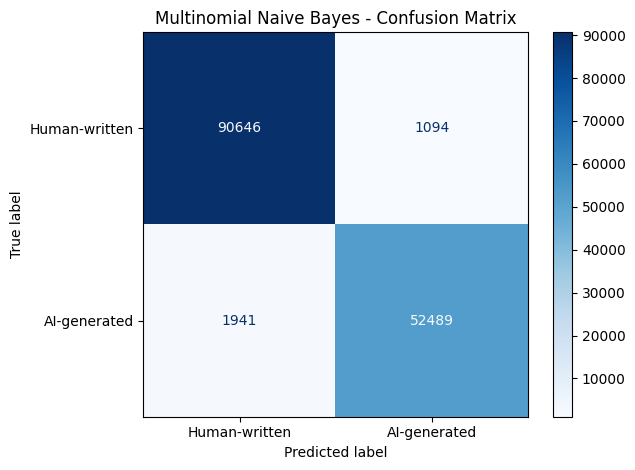

In [18]:
# Step 12: Train and Evaluate Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create the model
nb_model = MultinomialNB(alpha=0.1)

# Train the model using TF-IDF features
nb_model.fit(X_train_tfidf, y_train)

# Predict the test data
nb_predictions = nb_model.predict(X_test_tfidf)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("MULTINOMIAL NAIVE BAYES RESULTS")
print("-" * 40)
print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Naive Bayes Accuracy: {nb_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Human-written", "AI-generated"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, nb_predictions))

# Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    display_labels=["Human-written", "AI-generated"],
    cmap="Blues"
)
plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.show()


LOGISTIC REGRESSION RESULTS
----------------------------------------
Baseline Accuracy: 62.76%
Naive Bayes Accuracy: 97.92%
Logistic Regression Accuracy: 99.71%

Classification Report:
               precision    recall  f1-score   support

Human-written       1.00      1.00      1.00     91740
 AI-generated       1.00      0.99      1.00     54430

     accuracy                           1.00    146170
    macro avg       1.00      1.00      1.00    146170
 weighted avg       1.00      1.00      1.00    146170

Confusion Matrix:
[[91683    57]
 [  369 54061]]


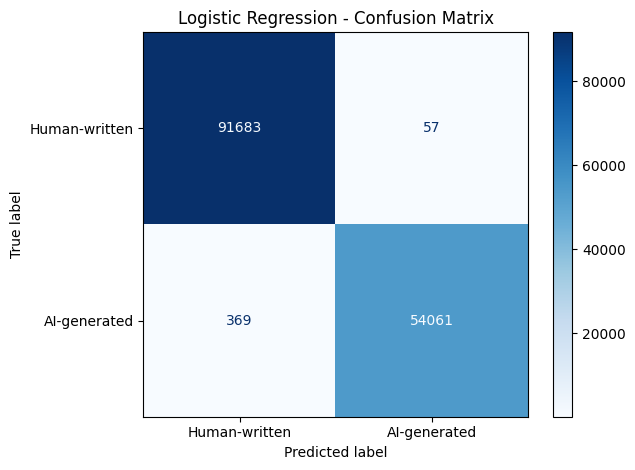

In [19]:

# Step 13: Train and Evaluate Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create the model
lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict the test data
lr_predictions = lr_model.predict(X_test_tfidf)

# Evaluate
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)
print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Naive Bayes Accuracy: {nb_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Human-written", "AI-generated"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=["Human-written", "AI-generated"],
    cmap="Blues"
)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [20]:

# Step 14: Train Linear SVM

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Create the model
svm_model = LinearSVC(
    C=1.0,
    max_iter=2000,
    random_state=42
)

# Train using training data only
svm_model.fit(X_train_tfidf, y_train)

print("LINEAR SVM TRAINING COMPLETE")
print("-" * 40)
print("Training records:", f"{X_train_tfidf.shape[0]:,}")
print("TF-IDF features:", f"{X_train_tfidf.shape[1]:,}")
print("Model:", "Linear Support Vector Machine")
print("Regularization parameter (C):", svm_model.C)
print("Maximum iterations:", svm_model.max_iter)


LINEAR SVM TRAINING COMPLETE
----------------------------------------
Training records: 341,061
TF-IDF features: 50,000
Model: Linear Support Vector Machine
Regularization parameter (C): 1.0
Maximum iterations: 2000


In [ ]:

# Step 15: Tune Logistic Regression using 3-fold cross-validation

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build a leakage-safe pipeline
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ))
])

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Tune the regularization parameter
lr_param_grid = {
    "classifier__C": [0.5, 1.0]
}

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True
)

print("Starting Logistic Regression tuning...")
print("This may take a while because the dataset is large.")

lr_grid_search.fit(X_train, y_train)

print("\nLOGISTIC REGRESSION TUNING RESULTS")
print("-" * 40)
print("Best parameters:", lr_grid_search.best_params_)
print("Best mean CV macro F1:", round(lr_grid_search.best_score_, 4))

print("\nAll cross-validation results:")
for mean_score, params in zip(
    lr_grid_search.cv_results_["mean_test_score"],
    lr_grid_search.cv_results_["params"]
):
    print(f"Macro F1: {mean_score:.4f} | Parameters: {params}")


Starting Logistic Regression tuning...
This may take a while because the dataset is large.
Fitting 3 folds for each of 2 candidates, totalling 6 fits
[CV] END ..................................classifier__C=0.5; total time= 3.6min


In [ ]:

# Step 16: Tune Linear SVM using 3-fold cross-validation

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build a leakage-safe pipeline
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        max_iter=2000,
        random_state=42
    ))
])

# Use the same cross-validation configuration
svm_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Tune the regularization parameter
svm_param_grid = {
    "classifier__C": [0.5, 1.0]
}

svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=svm_cv,
    n_jobs=1,
    verbose=2,
    refit=True
)

print("Starting Linear SVM tuning...")
print("This may take several minutes.")

svm_grid_search.fit(X_train, y_train)

print("\nLINEAR SVM TUNING RESULTS")
print("-" * 40)
print("Best parameters:", svm_grid_search.best_params_)
print("Best mean CV macro F1:", round(svm_grid_search.best_score_, 4))

print("\nAll cross-validation results:")
for mean_score, params in zip(
    svm_grid_search.cv_results_["mean_test_score"],
    svm_grid_search.cv_results_["params"]
):
    print(f"Macro F1: {mean_score:.4f} | Parameters: {params}")


In [ ]:

# Step 17: Final test-set comparison

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the best models selected by cross-validation
tuned_lr_model = lr_grid_search.best_estimator_
tuned_svm_model = svm_grid_search.best_estimator_

# Predictions on the held-out test set
nb_final_pred = nb_model.predict(X_test_tfidf)
lr_final_pred = tuned_lr_model.predict(X_test)
svm_final_pred = tuned_svm_model.predict(X_test)

# Model scores for ROC-AUC
nb_scores = nb_model.predict_proba(X_test_tfidf)[:, 1]
lr_scores = tuned_lr_model.predict_proba(X_test)[:, 1]
svm_scores = tuned_svm_model.decision_function(X_test)

# Create a comparison table
models = {
    "Multinomial Naive Bayes": (nb_final_pred, nb_scores),
    "Tuned Logistic Regression": (lr_final_pred, lr_scores),
    "Tuned Linear SVM": (svm_final_pred, svm_scores)
}

comparison_results = []

for model_name, (predictions, scores) in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

comparison_df = pd.DataFrame(comparison_results)
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

print("Selected Logistic Regression parameters:",
      lr_grid_search.best_params_)
print("Selected Linear SVM parameters:",
      svm_grid_search.best_params_)


In [ ]:

# Step 18: Error Analysis for the Tuned Linear SVM

from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# Predict using the tuned Linear SVM
svm_final_pred = tuned_svm_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, svm_final_pred)

print("LINEAR SVM - ERROR ANALYSIS")
print("-" * 40)
print("Confusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_test,
    svm_final_pred,
    target_names=["Human-written", "AI-generated"],
    digits=5,
    zero_division=0
))

# Find incorrect predictions
errors = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual_label": y_test.reset_index(drop=True),
    "predicted_label": pd.Series(svm_final_pred)
})

errors = errors[errors["actual_label"] != errors["predicted_label"]].copy()

errors["actual_label"] = errors["actual_label"].map({
    0: "Human-written",
    1: "AI-generated"
})

errors["predicted_label"] = errors["predicted_label"].map({
    0: "Human-written",
    1: "AI-generated"
})

print("\nTotal misclassified records:", len(errors))
print("\nError types:")
print(pd.crosstab(
    errors["actual_label"],
    errors["predicted_label"]
))

# Show up to five examples for manual inspection
print("\nSAMPLE MISCLASSIFIED TEXTS")
for i, (_, row) in enumerate(errors.head(5).iterrows(), start=1):
    print(f"\nExample {i}")
    print("Actual:", row["actual_label"])
    print("Predicted:", row["predicted_label"])
    print("Text:", row["text"][:700].replace("\n", " "))
    print("-" * 60)


In [ ]:

# Step 19: Check for exact text overlap and unusual text patterns

import hashlib
import re

# Normalize text for duplicate checking
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_normalized = X_train.map(normalize_text)
test_normalized = X_test.map(normalize_text)

# Exact overlap after basic normalization
train_text_set = set(train_normalized)
test_overlap_count = test_normalized.isin(train_text_set).sum()

print("DATASET ARTIFACT CHECK")
print("-" * 40)
print("Training records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")
print("Test records matching normalized training text:",
      f"{test_overlap_count:,}")

# Inspect unusual character patterns in error examples
print("\nTEXT PATTERN CHECK")
print("-" * 40)

if len(errors) > 0:
    error_texts = errors["text"].astype(str)

    print("Error records:", len(error_texts))
    print("Average character count:",
          round(error_texts.str.len().mean(), 2))
    print("Records containing repeated character runs (3+):",
          error_texts.str.count(r"(.)\1{2,}").gt(0).sum())

else:
    print("No misclassified records to inspect.")


In [ ]:
import re

print("ERROR TEXT PATTERN CHECK")
print("-" * 40)

error_texts = errors["text"].fillna("").astype(str)

# Repeated character runs, such as "hellooo" or "!!!!!"
repeated_runs = error_texts.str.contains(
    r"(.)\1{2,}",
    regex=True
)

# Wrap [a-z] in a capturing group so that \1 refers to it correctly
repeated_letter_words = error_texts.str.contains(
    r"\b\w*([a-z])\1{2,}\w*\b",
    case=False,
    regex=True
)

print("Total misclassified records:", len(error_texts))
print("Average character count:", round(error_texts.str.len().mean(), 2))
print("Records with repeated character runs:", int(repeated_runs.sum()))
print(
    "Records with unusual repeated-letter words:",
    int(repeated_letter_words.sum())
)

print("\nExamples of misclassified text (first 3):")
for i, text in enumerate(error_texts.head(3), start=1):
    print(f"\nExample {i}:")
    print(text[:300].replace("\n", " "))

In [ ]:

import hashlib
import re
import pandas as pd

def normalized_text_hash(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Hash training text and retain its corresponding labels
train_hashes = pd.DataFrame({
    "text_hash": X_train.map(normalized_text_hash),
    "label": y_train.to_numpy()
})

# Match normalized test texts against training texts
test_hashes = pd.DataFrame({
    "text_hash": X_test.map(normalized_text_hash),
    "label": y_test.to_numpy()
})

overlap = test_hashes.merge(
    train_hashes.drop_duplicates(),
    on="text_hash",
    how="inner",
    suffixes=("_test", "_train")
)

# Each matching text can potentially appear with more than one label.
overlap["label_match"] = (
    overlap["label_test"] == overlap["label_train"]
)

print("OVERLAP LABEL CHECK")
print("-" * 40)
print("Matching text-label pairs:", len(overlap))
print("Pairs with matching labels:", int(overlap["label_match"].sum()))
print("Pairs with different labels:", int((~overlap["label_match"]).sum()))
print("\nLabel-pair counts:")
print(
    overlap.groupby(["label_train", "label_test"])
    .size()
    .rename("count")
    .to_string()
)


In [ ]:

import hashlib
import re
import pandas as pd

def normalized_text_hash(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

train_hashes = pd.DataFrame({
    "text_hash": X_train.map(normalized_text_hash),
    "label": y_train.to_numpy()
})

test_hashes = pd.DataFrame({
    "text_hash": X_test.map(normalized_text_hash),
    "label": y_test.to_numpy()
})

overlap = test_hashes.merge(
    train_hashes.drop_duplicates(),
    on="text_hash",
    how="inner",
    suffixes=("_test", "_train")
)

overlap["label_match"] = (
    overlap["label_test"] == overlap["label_train"]
)

print("Matching normalized texts:", len(overlap))
print("Matching labels:", int(overlap["label_match"].sum()))
print("Different labels:", int((~overlap["label_match"]).sum()))


In [ ]:

# Find normalized text hashes with conflicting labels in training
label_counts = train_hashes.groupby("text_hash")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

print("Training text hashes with multiple labels:", len(conflicting_hashes))

# Show the two train/test pairs with different labels
conflicting_overlap = overlap.loc[
    ~overlap["label_match"]
].copy()

print("\nConflicting train/test pairs:")
print(
    conflicting_overlap[
        ["text_hash", "label_test", "label_train"]
    ].to_string(index=False)
)


In [ ]:

# Inspect the conflicting normalized texts and their labels
conflicting_hashes = conflicting_overlap["text_hash"].tolist()

train_text_hashes = X_train.map(normalized_text_hash)
test_text_hashes = X_test.map(normalized_text_hash)

for i, text_hash in enumerate(conflicting_hashes, start=1):
    print(f"\n{'=' * 60}")
    print(f"CONFLICT {i}")
    print("=" * 60)

    train_indices = train_text_hashes[
        train_text_hashes == text_hash
    ].index

    test_indices = test_text_hashes[
        test_text_hashes == text_hash
    ].index

    print("\nTraining records:")
    for idx in train_indices[:2]:
        print("Label:", y_train.loc[idx])
        print("Text:", str(X_train.loc[idx])[:500])

    print("\nTesting records:")
    for idx in test_indices[:2]:
        print("Label:", y_test.loc[idx])
        print("Text:", str(X_test.loc[idx])[:500])


Conflict 1 — School lunch essay
The training copy is labeled Human (0), while the testing copy is labeled AI (1). The visible text is effectively identical.



Conflict 2 — Generic_City essay
The training copy is labeled AI (1), while the testing copy is labeled Human (0). Again, the visible text is effectively identical.

In [ ]:

# Inspect normalized texts assigned multiple labels within training
for i, text_hash in enumerate(conflicting_hashes, start=1):
    print(f"\n{'=' * 60}")
    print(f"TRAINING LABEL CONFLICT {i}")
    print("=" * 60)

    indices = train_text_hashes[
        train_text_hashes == text_hash
    ].index

    for idx in indices:
        print("Label:", y_train.loc[idx])
        print("Text:", str(X_train.loc[idx])[:400])
        print("-" * 30)


In [ ]:

print("TRAINING LABEL CONFLICT SUMMARY")
print("-" * 40)

label_counts = train_hashes.groupby("text_hash")["label"].nunique()
conflict_hashes = label_counts[label_counts > 1].index

print("Number of hashes with conflicting labels:", len(conflict_hashes))

for text_hash in conflict_hashes:
    labels = sorted(
        train_hashes.loc[
            train_hashes["text_hash"] == text_hash, "label"
        ].unique().tolist()
    )
    count = (train_hashes["text_hash"] == text_hash).sum()
    print(f"Labels: {labels} | Training records: {count}")


In [ ]:
print("Tuned SVM model available:", "tuned_svm_model" in globals())
print("Tuned Logistic Regression available:", "tuned_lr_model" in globals())
print("TF-IDF vectorizer available:", "tfidf" in globals())

In [ ]:
print("Tuned SVM pipeline steps:")
print(tuned_svm_model)

print("\nTuned Logistic Regression pipeline steps:")
print(tuned_lr_model)

print("\nSVM pipeline step names:")
print(tuned_svm_model.named_steps.keys())

print("\nLogistic Regression pipeline step names:")
print(tuned_lr_model.named_steps.keys())

In [ ]:
import pandas as pd
import numpy as np

# Get the trained TF-IDF vectorizer and SVM classifier
svm_vectorizer = tuned_svm_model.named_steps["tfidf"]
svm_classifier = tuned_svm_model.named_steps["classifier"]

# Get feature names and model coefficients
feature_names = svm_vectorizer.get_feature_names_out()
coefficients = svm_classifier.coef_.ravel()

# Largest positive coefficients indicate AI (label 1)
top_ai_indices = np.argsort(coefficients)[-15:][::-1]

# Largest negative coefficients indicate Human (label 0)
top_human_indices = np.argsort(coefficients)[:15]

# Display the results
top_ai_features = pd.DataFrame({
    "Word or Phrase": feature_names[top_ai_indices],
    "SVM Coefficient": coefficients[top_ai_indices]
})

top_human_features = pd.DataFrame({
    "Word or Phrase": feature_names[top_human_indices],
    "SVM Coefficient": coefficients[top_human_indices]
})

print("Top 15 features associated with AI predictions:")
display(top_ai_features)

print("\nTop 15 features associated with Human predictions:")
display(top_human_features)

### Model Interpretation Using Linear SVM

To understand the decisions made by the Linear Support Vector Machine (SVM), we examined the model coefficients associated with the TF-IDF features.

Features with positive coefficients push predictions toward the AI-generated class (label 1), while features with negative coefficients push predictions toward the Human-generated class (label 0).

The strongest AI-associated features included *additionally*, *essay*, *important*, *essential*, and *firstly*. The strongest Human-associated features included *people*, *venus*, *student_name*, *probably*, and *percent*.

These results suggest that the model learned associations between certain words or phrases and the labels in the training dataset. However, these associations do not prove authorship. They may reflect writing style, subject matter, templates, or dataset-specific patterns. Therefore, the model should be treated as a text classifier rather than a definitive AI-authorship detector.

**Why this mattered (later finding):** Because the strongest AI-associated features were common formal words such as *additionally*, *essential*, and *important*, well-written human text that used these words was often classified as AI-generated. Testing with known human-written texts confirmed these false "AI" flags (Steps 20 to 24).

The improved model in Steps 20 to 27 addresses this by keeping function words, adding punctuation and character n-gram (writing-style) features, training on short text snippets as well as full essays, adding human-written blogs and news articles to the training data, and using a tuned AI threshold with an "Uncertain" zone.

In [ ]:
print("Logistic Regression supports predict_proba:",
      hasattr(tuned_lr_model, "predict_proba"))

print("SVM supports predict_proba:",
      hasattr(tuned_svm_model, "predict_proba"))

In [ ]:
# Example texts for testing the prediction demo
sample_texts = [
    "Additionally, it is essential to consider the potential benefits of this approach.",
    "I think people should have more time because everyone has different things to do."
]

# Predict labels and probabilities using the existing model
predictions = tuned_lr_model.predict(sample_texts)
probabilities = tuned_lr_model.predict_proba(sample_texts)

# Get the class labels in the same order as the probability columns
class_labels = tuned_lr_model.classes_

for i, text in enumerate(sample_texts):
    probability_by_class = dict(zip(class_labels, probabilities[i]))

    human_percentage = probability_by_class[0] * 100
    ai_percentage = probability_by_class[1] * 100

    predicted_label = "AI-generated" if predictions[i] == 1 else "Human-generated"

    print(f"\nText: {text}")
    print(f"Predicted class: {predicted_label}")
    print(f"Estimated Human probability: {human_percentage:.2f}%")
    print(f"Estimated AI probability: {ai_percentage:.2f}%")

### Prediction Demonstration

The original Logistic Regression pipeline was tested using two new example sentences. The first sentence, which used formal expressions such as "additionally" and "essential," was classified as AI-generated with a displayed AI probability of 100.00%. The second, more informal sentence was classified as Human-generated, with an estimated Human probability of 81.14% and AI probability of 18.86%.

This demonstration confirmed that the pipeline can accept new text, predict a class, and return estimated probabilities. However, later testing showed that this original model also labelled many genuinely human-written texts as AI-generated, especially short or formally written ones.

**Updated result with the final model (Steps 20 to 27):** The final model (Model v2) returns one of three outcomes: **Human-Written**, **Uncertain**, or **AI-Generated**. It uses an AI threshold of 0.65 and never labels texts under 50 words as AI. In a test with three AI-written paragraphs and three paragraphs known to be human-written:

| Text | Original model | Final model |
|---|---|---|
| AI samples 1 to 3 | AI (99.0% to 99.7%) | AI (99.4% to 100.0%) |
| Human sample 1 | Human (27.9% AI) | Human (2.2% AI) |
| Human sample 2 | **AI (68.2% AI)** | Human (14.8% AI) |
| Human sample 3 | **AI (65.1% AI)** | Human (27.3% AI) |

On held-out test data, short human-written essay snippets wrongly labelled as AI fell from 8.5% (original recipe) to 0.4%, and short human-written blog and news snippets fell from 4.3% (first improved model) to 0.1%. The final model still detects 96.8% of full-length AI-generated essays.

These probabilities are model outputs and should not be interpreted as definitive proof of authorship.

In [ ]:
import os

print("Current directory:", os.getcwd())
print("\nSaved model-related files:")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".pkl", ".joblib")):
            print(os.path.join(root, file))

In [ ]:
import os
import joblib

# Create a folder for saved models
model_dir = "/content/saved_models"
os.makedirs(model_dir, exist_ok=True)

# Save the existing trained pipelines
joblib.dump(
    tuned_svm_model,
    os.path.join(model_dir, "tuned_svm_pipeline.joblib")
)

joblib.dump(
    tuned_lr_model,
    os.path.join(model_dir, "tuned_logistic_regression_pipeline.joblib")
)

print("Models saved successfully!")

print("\nSaved files:")
for file in os.listdir(model_dir):
    file_path = os.path.join(model_dir, file)
    print(f"{file}: {os.path.getsize(file_path) / (1024 * 1024):.2f} MB")

In [ ]:
import joblib
import os

model_dir = "/content/saved_models"

svm_path = os.path.join(model_dir, "tuned_svm_pipeline.joblib")
lr_path = os.path.join(
    model_dir,
    "tuned_logistic_regression_pipeline.joblib"
)

# Load the saved models
loaded_svm = joblib.load(svm_path)
loaded_lr = joblib.load(lr_path)

# Test both models on new text
test_text = [
    "I believe students should have more time to complete their assignments."
]

svm_prediction = loaded_svm.predict(test_text)[0]
lr_prediction = loaded_lr.predict(test_text)[0]
lr_probabilities = loaded_lr.predict_proba(test_text)[0]

print("SVM loaded successfully:", type(loaded_svm).__name__)
print("Logistic Regression loaded successfully:", type(loaded_lr).__name__)

print("\nSVM prediction:",
      "AI-generated" if svm_prediction == 1 else "Human-generated")

print("Logistic Regression prediction:",
      "AI-generated" if lr_prediction == 1 else "Human-generated")

print(f"Estimated Human probability: {lr_probabilities[0] * 100:.2f}%")
print(f"Estimated AI probability: {lr_probabilities[1] * 100:.2f}%")

In [ ]:
checks = {
    "Cleaned dataset": "df" in globals(),
    "Training features": "X_train" in globals(),
    "Testing features": "X_test" in globals(),
    "Baseline model": "baseline_model" in globals(),
    "Naive Bayes model": "nb_model" in globals(),
    "Tuned SVM pipeline": "tuned_svm_model" in globals(),
    "Tuned Logistic Regression pipeline": "tuned_lr_model" in globals(),
}

print("PROJECT ARTIFACT CHECK")
print("-" * 40)

for item, available in checks.items():
    print(f"{item}: {'Available' if available else 'Not available'}")

In [ ]:
test_texts = [
    "I believe students should have more time to complete their assignments.",
    "Additionally, it is essential to consider the potential benefits of this approach."
]

original_svm_predictions = tuned_svm_model.predict(test_texts)
loaded_svm_predictions = loaded_svm.predict(test_texts)

original_lr_predictions = tuned_lr_model.predict(test_texts)
loaded_lr_predictions = loaded_lr.predict(test_texts)

print("SVM predictions match:",
      (original_svm_predictions == loaded_svm_predictions).all())

print("Logistic Regression predictions match:",
      (original_lr_predictions == loaded_lr_predictions).all())

print("\nSaved-model verification complete.")

In [ ]:
final_results = pd.DataFrame([
    {
        "Model": "Dummy Baseline",
        "Accuracy": 0.6276,
        "Macro Precision": None,
        "Macro Recall": None,
        "Macro F1": None,
        "ROC-AUC": None
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": 0.9792,
        "Macro Precision": 0.9793,
        "Macro Recall": 0.9762,
        "Macro F1": 0.9777,
        "ROC-AUC": 0.9976
    },
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": 0.9970,
        "Macro Precision": 0.9974,
        "Macro Recall": 0.9962,
        "Macro F1": 0.9968,
        "ROC-AUC": 0.9999
    },
    {
        "Model": "Tuned Linear SVM",
        "Accuracy": 0.9995,
        "Macro Precision": 0.9995,
        "Macro Recall": 0.9993,
        "Macro F1": 0.9994,
        "ROC-AUC": 1.0000
    }
])

display(final_results.round(4))

final_results.to_csv(
    "/content/final_model_comparison.csv",
    index=False
)

print("Corrected comparison table saved.")

In [ ]:
# Final prediction demo

def predict_text_origin(text):
    if not isinstance(text, str) or not text.strip():
        print("Please enter some text.")
        return

    prediction = loaded_lr.predict([text])[0]
    probabilities = loaded_lr.predict_proba([text])[0]

    human_probability = probabilities[0] * 100
    ai_probability = probabilities[1] * 100

    predicted_label = "AI-Generated" if prediction == 1 else "Human-Written"

    print("=" * 45)
    print("TEXT ORIGIN CLASSIFICATION")
    print("=" * 45)
    print(f"Prediction: {predicted_label}")
    print(f"Estimated Human probability: {human_probability:.2f}%")
    print(f"Estimated AI probability: {ai_probability:.2f}%")
    print("-" * 45)
    print("Note: These are model estimates, not proof of authorship.")

In [ ]:
sample_text = """
I believe students should have enough time to complete their
assignments because every student has different responsibilities.
"""

predict_text_origin(sample_text)

In [ ]:
# Step 20: Fixing false "AI" flags on human-written text
# ---------------------------------------------------------------------------
# Why the earlier model flags human text as AI:
#  1. stop_words="english" removed function words (I, the, because, but ...),
#     which carry most of the writing-style signal. The model leaned on topic /
#     formal words such as "additionally", "essential", "important" instead.
#  2. It was trained only on full essays (~400 words) but is used on short
#     sentences it has never seen, so it gives overconfident guesses.
#  3. A fixed 0.5 threshold turns anything slightly formal into "AI".
# Fixes below: keep function words + add character n-grams (style features),
# train on short snippets as well as full essays, and choose the AI threshold
# on validation data so that very few human texts get flagged.

import os, re, gc
import numpy as np
import pandas as pd
import kagglehub
from sklearn.model_selection import train_test_split

if "df" not in globals():
    data_dir = kagglehub.dataset_download("shanegerami/ai-vs-human-text")
    df = pd.read_csv(os.path.join(data_dir, "AI_Human.csv"))
    df = df[df["text"].astype(str).str.strip().ne("")].reset_index(drop=True)
df["generated"] = df["generated"].astype(int)

# Same 70:30 split as Step 9.1, so the test part is never used for training
X_tr_all, X_te_all, y_tr_all, y_te_all = train_test_split(
    df["text"], df["generated"], test_size=0.30, random_state=42, stratify=df["generated"]
)

# Subsample to keep memory and time manageable on a free Colab runtime
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_all, y_tr_all, train_size=40_000, test_size=15_000, random_state=42, stratify=y_tr_all
)
X_te, _, y_te, _ = train_test_split(
    X_te_all, y_te_all, train_size=20_000, random_state=42, stratify=y_te_all
)
X_tr, X_val, X_te = X_tr.astype(str), X_val.astype(str), X_te.astype(str)
del df, X_tr_all, X_te_all, y_tr_all, y_te_all
gc.collect()

rng = np.random.default_rng(42)

def random_snippet(text, min_words=15, max_words=150):
    """Cut a random passage of 15-150 words, to mimic short user inputs."""
    words = str(text).split()
    if len(words) <= min_words:
        return " ".join(words)
    length = int(rng.integers(min_words, min(max_words, len(words)) + 1))
    start = int(rng.integers(0, len(words) - length + 1))
    return " ".join(words[start:start + length])

def add_snippets(X, y):
    snippets = X.map(random_snippet)
    return (pd.concat([X, snippets], ignore_index=True),
            pd.concat([y, y], ignore_index=True))

X_tr_aug, y_tr_aug = add_snippets(X_tr, y_tr)
X_val_aug, y_val_aug = add_snippets(X_val, y_val)
X_te_short = X_te.map(random_snippet)          # short-text version of the test set

print("Training rows (essays + snippets):", f"{len(X_tr_aug):,}")
print("Validation rows (essays + snippets):", f"{len(X_val_aug):,}")
print("Test rows (full essays):", f"{len(X_te):,}")
print("Test rows (short snippets):", f"{len(X_te_short):,}")


In [ ]:
# Step 21: Train the old recipe and the improved recipe on the same data
import time
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def clean_text(text):
    text = str(text).lower()
    for a, b in {"’": "'", "‘": "'", "“": '"', "”": '"'}.items():
        text = text.replace(a, b)
    return re.sub(r"\s+", " ", text).strip()

# Old recipe (same settings as Step 15), trained on full essays only
old_style_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=30000, stop_words="english", ngram_range=(1, 2),
                              min_df=2, max_df=0.95, sublinear_tf=True)),
    ("classifier", LogisticRegression(C=1.0, max_iter=1000, solver="liblinear", random_state=42)),
])

# Improved recipe: function words + punctuation + character n-grams, more regularisation
improved_model = Pipeline([
    ("features", FeatureUnion([
        ("words", TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2),
                                  token_pattern=r"(?u)\b\w+\b|[^\w\s]",
                                  min_df=3, max_df=0.9, max_features=100_000,
                                  sublinear_tf=True, dtype=np.float32)),
        ("chars", TfidfVectorizer(preprocessor=clean_text, analyzer="char_wb",
                                  ngram_range=(3, 5), min_df=5, max_features=150_000,
                                  sublinear_tf=True, dtype=np.float32)),
    ])),
    ("classifier", LogisticRegression(C=0.5, max_iter=2000, solver="liblinear", random_state=42)),
])

start = time.time()
old_style_model.fit(X_tr, y_tr)
print(f"Old-recipe model trained in {time.time() - start:.0f} s")

start = time.time()
improved_model.fit(X_tr_aug, y_tr_aug)
print(f"Improved model trained in {time.time() - start:.0f} s")


In [ ]:
# Step 22: Pick a safer AI threshold and compare false "AI" flags on human text
from sklearn.metrics import confusion_matrix, roc_auc_score

# Threshold chosen on validation data: at most ~1% of human texts may be flagged as AI
val_ai_prob = improved_model.predict_proba(X_val_aug)[:, 1]
human_val_prob = val_ai_prob[y_val_aug.to_numpy() == 0]
ai_threshold = float(max(0.5, np.quantile(human_val_prob, 0.99)))
print(f"Chosen AI threshold: {ai_threshold:.3f}\n")

rows = []
for test_name, X_eval in [("Full essays", X_te), ("Short snippets", X_te_short)]:
    for model_name, model, thr in [("Old recipe, 0.5 threshold", old_style_model, 0.5),
                                   ("Improved recipe + tuned threshold", improved_model, ai_threshold)]:
        p = model.predict_proba(X_eval)[:, 1]
        pred = (p >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
        rows.append({
            "Test set": test_name,
            "Model": model_name,
            "Accuracy": (tp + tn) / len(pred),
            "Human flagged as AI (%)": 100 * fp / (fp + tn),
            "AI correctly caught (%)": 100 * tp / (tp + fn),
            "ROC-AUC": roc_auc_score(y_te, p),
        })

comparison = pd.DataFrame(rows)
display(comparison.round(3))


In [ ]:
# Step 23: Updated prediction function ("Uncertain" zone + short-text guard)
import joblib, json

MIN_WORDS = 50   # training essays average ~390 words; very short inputs are unreliable

def predict_text_origin(text, model=None, threshold=None, show=True):
    model = model or improved_model
    threshold = threshold if threshold is not None else ai_threshold
    if not isinstance(text, str) or not text.strip():
        print("Please enter some text.")
        return None
    ai_prob = float(model.predict_proba([text])[0, 1])
    n_words = len(text.split())
    if ai_prob >= threshold:
        label = "AI-Generated (likely)"
    elif ai_prob < 0.5:
        label = "Human-Written (likely)"
    else:
        label = "Uncertain"
    if n_words < MIN_WORDS and label.startswith("AI"):
        label = "Uncertain (text too short to judge reliably)"
    if show:
        print("=" * 50)
        print("TEXT ORIGIN CLASSIFICATION")
        print("=" * 50)
        print(f"Prediction: {label}")
        print(f"Estimated AI probability: {ai_prob * 100:.2f}%  (AI threshold: {threshold * 100:.1f}%)")
        print(f"Word count: {n_words}")
        print("-" * 50)
        print("Note: These are model estimates, not proof of authorship.")
    return label, ai_prob

# Human-style examples (add your own texts that were wrongly flagged here)
human_examples = [
    "I believe students should have enough time to complete their assignments because every student has different responsibilities.",
    "Honestly I wasn't sure the bus would come on time, so I left early and ended up waiting twenty minutes in the rain. Next time I'm just walking.",
    "The committee met on Tuesday to review the budget. After a long discussion, members agreed to postpone buying new equipment until next year, mainly because the current funds are needed to repair the school building.",
    "My grandmother taught me to cook dal when I was ten. She never measured anything; she would just look at the pot and say it needs a little more salt. I still cook it her way, although mine never tastes quite the same.",
    "In my opinion, schools should start later in the morning. Many teenagers stay up late doing homework, and when they come to class tired they cannot concentrate. A later start would help students learn better and also be safer for those who drive.",
]

rows = []
for t in human_examples:
    old_p = old_style_model.predict_proba([t])[0, 1]
    new_label, new_p = predict_text_origin(t, show=False)
    rows.append({
        "Text (start)": t[:60] + "...",
        "Old AI prob (%)": round(old_p * 100, 1),
        "Old prediction": "AI" if old_p >= 0.5 else "Human",
        "New AI prob (%)": round(new_p * 100, 1),
        "New prediction": new_label,
    })
display(pd.DataFrame(rows))

# Save the improved model and its threshold for the Streamlit app
model_dir = "/content/saved_models"
os.makedirs(model_dir, exist_ok=True)
joblib.dump(improved_model, os.path.join(model_dir, "improved_lr_pipeline.joblib"))
with open(os.path.join(model_dir, "improved_model_config.json"), "w") as f:
    json.dump({"ai_threshold": ai_threshold, "min_words": MIN_WORDS}, f)
print("\nSaved:", os.listdir(model_dir))


In [ ]:
val_y = y_val_aug.to_numpy(); yt = y_te.to_numpy(); thresholds = np.round(np.arange(0.50, 0.96, 0.05), 2); sweep = pd.DataFrame([{"Threshold": t, "Human flagged as AI (%)": 100 * (val_ai_prob[val_y == 0] >= t).mean(), "AI correctly caught (%)": 100 * (val_ai_prob[val_y == 1] >= t).mean()} for t in thresholds]); print("VALIDATION THRESHOLD SWEEP"); print(sweep.round(2).to_string(index=False)); ai_threshold = float(sweep.loc[sweep["AI correctly caught (%)"] >= 90, "Threshold"].max()); print("\nNew conservative AI threshold:", ai_threshold, "- scores between 50% and this are reported as Uncertain"); json.dump({"ai_threshold": ai_threshold, "min_words": MIN_WORDS}, open(os.path.join(model_dir, "improved_model_config.json"), "w")); p_full = improved_model.predict_proba(X_te)[:, 1]; p_short = improved_model.predict_proba(X_te_short)[:, 1]; print("\nTEST SET AT NEW THRESHOLD"); print(pd.DataFrame([{"Test set": n, "Human flagged as AI (%)": 100 * (p[yt == 0] >= ai_threshold).mean(), "Human marked Uncertain (%)": 100 * ((p[yt == 0] >= 0.5) & (p[yt == 0] < ai_threshold)).mean(), "AI correctly caught (%)": 100 * (p[yt == 1] >= ai_threshold).mean()} for n, p in [("Full essays", p_full), ("Short snippets", p_short)]]).round(2).to_string(index=False))

In [ ]:
# Step 24: Dry test - AI-written samples vs your own human-written samples
# Run Steps 20-23 first. AI samples are filled in; paste your own human text below.

ai_texts = [
    """Social media has transformed the way people communicate, offering both significant benefits and notable challenges. On one hand, platforms such as Instagram and Twitter allow individuals to stay connected with friends and family across great distances. They also provide valuable opportunities for businesses to reach wider audiences. On the other hand, excessive use of social media can contribute to feelings of anxiety, isolation, and low self-esteem, particularly among young people. Therefore, it is essential to strike a healthy balance between online engagement and real-world interactions in order to maximize the advantages while minimizing the potential drawbacks.""",

    """Online learning has become an increasingly popular alternative to traditional classroom education. One of its primary advantages is flexibility, as students can access course materials at any time and learn at their own pace. Additionally, online learning can reduce costs associated with commuting and accommodation. However, it also presents certain challenges, including limited face-to-face interaction and the need for strong self-discipline. In conclusion, while online learning offers numerous benefits, its effectiveness ultimately depends on the learner's motivation and the quality of the digital resources provided.""",

    """Regular physical activity plays a crucial role in maintaining overall health and well-being. Engaging in exercise helps strengthen the heart, improve muscle tone, and enhance flexibility. Furthermore, physical activity has been shown to reduce stress levels and improve mental health by releasing endorphins. It is important to note that even moderate activities, such as walking or cycling, can provide substantial benefits. By incorporating exercise into their daily routines, individuals can significantly lower their risk of chronic diseases and enjoy a higher quality of life.""",
]

# >>> Paste your own human-written texts between the triple quotes (add more lines if you want)
human_texts = [
    """Here’s why. I’m fully aware that most of what I read online these days is at the very least AI-assisted, if not entirely written by AI. Generally, I don’t mind. My main concern is whether what I’m reading is accurate or not. If I want to know how to operate my toaster, I don’t need to be assured that a human wrote the instructions. But when it comes to art and journalism, come on! With poetry, prose, etc., the whole point is the masterful placing of words in sentences, in paragraphs for the enjoyment and stirring of the reader.""",
    """We need writers who are free to express the concerns of their own heart and properly relate to the human condition. AI is censored. AI levels the playing field and not in a good way. It takes horrible writing and morphs it into bland, mediocre mush. It takes high quality writing and brings it down a peg, ensuring that all color is removed and the whole piece is grey. Probably a lot of writers would take an article like this, dump it into Claude and say, “clean this up”. Big mistake. The ensuing result would be a nice dainty pile of horse manure.""",
    """I know someone will say, “What if AI catches up and becomes able to write on the same level of nuance and subtlty that humans can?” Well firstly, AI will never be able to do that. Humans are uniquely wired with creative faculties that cannot be mimicked. Secondly, no matter how sophisticated AI writers get, we need human writers!""",
]

results = []
for expected, texts in [("AI", ai_texts), ("Human", human_texts)]:
    for i, text in enumerate(texts, start=1):
        text = text.strip()
        if not text or text.startswith("PASTE"):
            continue                                   # skip empty placeholders
        print(f"\n########## {expected} SAMPLE {i} ##########")
        print(text[:250] + ("..." if len(text) > 250 else ""))
        label, ai_prob = predict_text_origin(text)     # prints the model's full output
        old_prob = old_style_model.predict_proba([text])[0, 1]
        results.append({
            "Expected": expected,
            "Sample": i,
            "Words": len(text.split()),
            "Old model AI prob (%)": round(old_prob * 100, 1),
            "Old model says": "AI" if old_prob >= 0.5 else "Human",
            "New model AI prob (%)": round(ai_prob * 100, 1),
            "New model says": label,
            "New model correct?": label.startswith("AI") if expected == "AI" else not label.startswith("AI"),
        })

print("\n" + "=" * 60)
print("DRY TEST SUMMARY")
print("=" * 60)
summary = pd.DataFrame(results)
display(summary)

ai_rows = summary[summary["Expected"] == "AI"]
human_rows = summary[summary["Expected"] == "Human"]
print(f"AI samples detected as AI: {int(ai_rows['New model correct?'].sum())} / {len(ai_rows)}")
if len(human_rows):
    flagged = int((~human_rows["New model correct?"]).sum())
    print(f"Human samples wrongly flagged as AI: {flagged} / {len(human_rows)} "
          f"(old model: {int((human_rows['Old model says'] == 'AI').sum())} / {len(human_rows)})")
else:
    print("No human samples yet - paste your texts into human_texts and run again.")


In [ ]:
import glob
for f in glob.glob('/kaggle/input/**/*.csv', recursive=True):
    print(f, os.path.getsize(f) // 2**20, 'MB', pd.read_csv(f, nrows=3, encoding_errors='ignore').columns.tolist())


In [ ]:
# Step 25: Extra human-written text from other domains
# Blog Authorship Corpus (blogs from 2004) and BBC News (2004-05) were written
# long before AI text generators existed, so they are reliably human-written.
blog_path = glob.glob('/kaggle/input/**/blogtext.csv', recursive=True)[0]
bbc_path = glob.glob('/kaggle/input/**/bbc_data.csv', recursive=True)[0]

def tidy(s):
    s = s.astype(str).str.replace("urlLink", " ", regex=False)   # blog corpus link marker
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

blogs = tidy(pd.read_csv(blog_path, usecols=["text"], encoding_errors="ignore")["text"])
wc = blogs.str.split().str.len()
letters = blogs.str.count(r"[A-Za-z]") / blogs.str.len().clip(lower=1)
blogs = blogs[(wc >= 50) & (wc <= 800) & (letters > 0.6)].drop_duplicates()
blogs = blogs.sample(n=min(20_000, len(blogs)), random_state=42)

bbc = tidy(pd.read_csv(bbc_path)["data"]).drop_duplicates()

extra_human = pd.concat([blogs, bbc], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
n_test = int(0.20 * len(extra_human))
n_val = int(0.15 * len(extra_human))
extra_test = extra_human.iloc[:n_test]
extra_val = extra_human.iloc[n_test:n_test + n_val]
extra_train = extra_human.iloc[n_test + n_val:]
extra_test_short = extra_test.map(random_snippet)

print(f"Blog posts: {len(blogs):,} | BBC articles: {len(bbc):,}")
print(f"Extra human text -> train: {len(extra_train):,}, validation: {len(extra_val):,}, test: {len(extra_test):,}")

# How does the CURRENT model handle this unseen, non-essay human writing?
print(f"\nCURRENT MODEL on unseen blog/news human text (AI threshold {ai_threshold:.2f})")
for name, X in [("Full posts/articles", extra_test), ("Short snippets", extra_test_short)]:
    p = improved_model.predict_proba(X)[:, 1]
    print(f"{name:20s} flagged as AI: {100 * (p >= ai_threshold).mean():5.2f}% | "
          f"Uncertain: {100 * ((p >= 0.5) & (p < ai_threshold)).mean():5.2f}%")


In [ ]:
# Step 26: Retrain with the extra human text and compare with the current model
from sklearn.base import clone

extra_train_aug = pd.concat([extra_train, extra_train.map(random_snippet)], ignore_index=True)
X_tr_v2 = pd.concat([X_tr_aug, extra_train_aug], ignore_index=True)
y_tr_v2 = pd.concat([y_tr_aug, pd.Series(0, index=range(len(extra_train_aug)))], ignore_index=True)
print(f"Training rows: {len(X_tr_v2):,} (AI share {100 * y_tr_v2.mean():.1f}%)")

start = time.time()
model_v2 = clone(improved_model).fit(X_tr_v2, y_tr_v2)
print(f"Model v2 trained in {time.time() - start:.0f} s")

# Pick the threshold on validation data (original validation + extra human validation)
extra_val_aug = pd.concat([extra_val, extra_val.map(random_snippet)], ignore_index=True)
X_val_v2 = pd.concat([X_val_aug, extra_val_aug], ignore_index=True)
y_val_v2 = np.concatenate([y_val_aug.to_numpy(), np.zeros(len(extra_val_aug), dtype=int)])
pv = model_v2.predict_proba(X_val_v2)[:, 1]
cands = [t for t in np.round(np.arange(0.50, 0.96, 0.05), 2) if (pv[y_val_v2 == 1] >= t).mean() >= 0.90]
threshold_v2 = float(max(cands)) if cands else 0.5
print(f"Model v2 AI threshold: {threshold_v2:.2f}")

# Compare on held-out test data (never used for training or threshold choice)
yt = y_te.to_numpy()
rows = []
for model_name, m, thr in [("Current model", improved_model, ai_threshold), ("Model v2 (+blogs/news)", model_v2, threshold_v2)]:
    for test_name, X, y in [("Essays - full", X_te, yt), ("Essays - short", X_te_short, yt),
                            ("Blogs/news (human) - full", extra_test, np.zeros(len(extra_test), int)),
                            ("Blogs/news (human) - short", extra_test_short, np.zeros(len(extra_test), int))]:
        p = m.predict_proba(X)[:, 1]
        rows.append({"Model": model_name, "Test set": test_name,
                     "Human flagged as AI (%)": 100 * (p[y == 0] >= thr).mean(),
                     "Human Uncertain (%)": 100 * ((p[y == 0] >= 0.5) & (p[y == 0] < thr)).mean(),
                     "AI caught (%)": 100 * (p[y == 1] >= thr).mean() if (y == 1).any() else np.nan})
print("\nHELD-OUT TEST COMPARISON")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# Use model v2 from now on and save it
improved_model, ai_threshold = model_v2, threshold_v2
joblib.dump(improved_model, os.path.join(model_dir, "improved_lr_pipeline.joblib"))
json.dump({"ai_threshold": ai_threshold, "min_words": MIN_WORDS},
          open(os.path.join(model_dir, "improved_model_config.json"), "w"))
print("\nSaved model v2 + threshold. Re-run Step 24 to test your own texts.")


In [ ]:
print(f"AI threshold: {ai_threshold:.2f}"); print(pd.DataFrame([{"Expected": e, "Sample": i, "Words": len(t.split()), "AI prob (%)": round(100 * r[1], 1), "Model v2 says": r[0]} for e, ts in [("AI", ai_texts), ("Human", human_texts)] for i, t in enumerate(ts, start=1) for r in [predict_text_origin(t.strip(), show=False)]]).to_string(index=False))

In [ ]:
import shutil, inspect; out = "/kaggle/working/saved_models"; shutil.copytree(model_dir, out, dirs_exist_ok=True); open(os.path.join(out, "clean_text.py"), "w").write("import re\n\n" + inspect.getsource(clean_text)); shutil.make_archive("/kaggle/working/ai_text_detector_model", "zip", out); [print(os.path.join(r, f), round(os.path.getsize(os.path.join(r, f)) / 2**20, 2), "MB") for r, _, fs in os.walk("/kaggle/working") for f in fs if "/." not in r]